# Análisis Pinch del proceso continuo

Cuaderno NB1 del curso. Cinco corrientes, tabla del problema, cascada, curvas compuestas y Gran Curva Compuesta. Cada cifra que aparece en pantalla proviene de un campo del paquete `ship_toolkit`, sin aritmética en celda.

In [ ]:
# Public wheel asset of pre-release v0.2.1, verified by real download: 705792 bytes,
# SHA-256 0861A3AF5E2A5AED69DE236596FD42675B3240ED0AAB9DB18252B84B05CBCA9A.
WHEEL_URL = "https://github.com/iwolde/ship-toolkit-releases/releases/download/v0.2.1/ship_toolkit-0.2.1-py3-none-any.whl"

_REQUIRED = "0.2.1"

import importlib.metadata
import importlib.util
import subprocess
import sys

try:
    _version = importlib.metadata.version("ship-toolkit")
except importlib.metadata.PackageNotFoundError:
    _version = None

if importlib.util.find_spec("ship_toolkit") is None or (
    _version is not None and _version != _REQUIRED
):
    if not WHEEL_URL:
        raise RuntimeError("WHEEL_URL is empty: the wheel has not been published yet.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", WHEEL_URL], check=True)
    try:
        _version = importlib.metadata.version("ship-toolkit")
    except importlib.metadata.PackageNotFoundError:
        _version = None

if _version is None:
    import ship_toolkit
    _version = getattr(ship_toolkit, "__version__", "sin version")

print("ship-toolkit", _version)

## Como se ejecuta este cuaderno

En Colab la celda de preparacion instala el paquete desde el wheel de la pre-release cuando `WHEEL_URL` tiene valor.

Los datos llegan por `data_path` desde el paquete instalado. No se sube ningun archivo a mano y no se lee de Google Drive.

En ejecucion local desde el repositorio la celda de preparacion no instala nada.

In [1]:
from ship_toolkit import (
    apply_style,
    data_path,
    detect_pockets,
    gcc_deficit_at,
    gcc_surplus_at,
    load_streams,
    plot_composite_curves,
    plot_gcc,
    plot_stream_bars,
    problem_table,
    run_pinch,
)
from ship_toolkit.pinch import active_streams_at, band_table, pinch_levels_C
from ship_toolkit.verify import verify_first_law

apply_style()

## S1. El caso, cinco corrientes

Se carga la tabla del proceso continuo desde `c53_continuous_streams.csv`. El cargador devuelve objetos `Stream` con su clase, sus temperaturas de suministro y objetivo, su tasa de capacidad, su zona de planta y su coeficiente de película.

In [2]:
streams = load_streams(data_path("c53_continuous_streams.csv"))

for s in streams:
    print(
        f"{s.name}: clase {s.kind}, suministro {s.T_supply_C:.1f} °C, "
        f"objetivo {s.T_target_C:.1f} °C, CP {s.CP_kW_per_K:.2f} kW/K, "
        f"zona {s.zone}, htc {s.htc_kW_per_m2K:.3f} kW/(m2 K)"
    )

H1: clase hot, suministro 160.0 °C, objetivo 120.0 °C, CP 14.00 kW/K, zona Condensador de cabeza, htc 0.850 kW/(m2 K)
H2: clase hot, suministro 206.0 °C, objetivo 156.0 °C, CP 16.00 kW/K, zona Fondos de columna, htc 0.850 kW/(m2 K)
C1: clase cold, suministro 111.0 °C, objetivo 174.0 °C, CP 11.00 kW/K, zona Precalentador de alimentacion, htc 0.850 kW/(m2 K)
C2: clase cold, suministro 117.0 °C, objetivo 184.0 °C, CP 10.00 kW/K, zona Reciclo de solvente, htc 0.850 kW/(m2 K)
C3: clase cold, suministro 173.0 °C, objetivo 182.0 °C, CP 20.00 kW/K, zona Rehervidor, htc 0.850 kW/(m2 K)


In [ ]:
from ship_toolkit import Stream, validate_streams

# La corriente H1 se construye campo por campo a partir de su fila en la tabla del proceso.
corriente = Stream(
    name="H1",
    kind="hot",
    T_supply_C=160.0,
    T_target_C=120.0,
    CP_kW_per_K=14.0,
    zone="Condensador de cabeza",
    htc_kW_per_m2K=0.85,
)

SIGNIFICADO_CAMPOS = {
    "name": "etiqueta unica de la corriente en la tabla",
    "kind": "hot si cede calor al enfriarse, cold si lo recibe al calentarse",
    "T_supply_C": "temperatura de entrada de la corriente [C]",
    "T_target_C": "temperatura de salida de la corriente [C]",
    "CP_kW_per_K": "tasa de capacidad termica m_dot * cp [kW/K]",
    "zone": "zona de planta a la que pertenece la corriente",
    "htc_kW_per_m2K": "coeficiente de pelicula para el diseno de la red [kW/(m2 K)]",
}

for campo, valor in corriente.to_dict().items():
    print(f"{campo} = {valor}: {SIGNIFICADO_CAMPOS[campo]}")

errores = validate_streams([corriente])
print(f"Errores de validacion de la corriente H1: {errores}")
print(f"Deber de la corriente H1: {corriente.duty_kW:.1f} kW")

misma_corriente = corriente.to_dict() == streams[0].to_dict()
print(f"La corriente H1 coincide campo a campo con la primera fila cargada: {misma_corriente}")


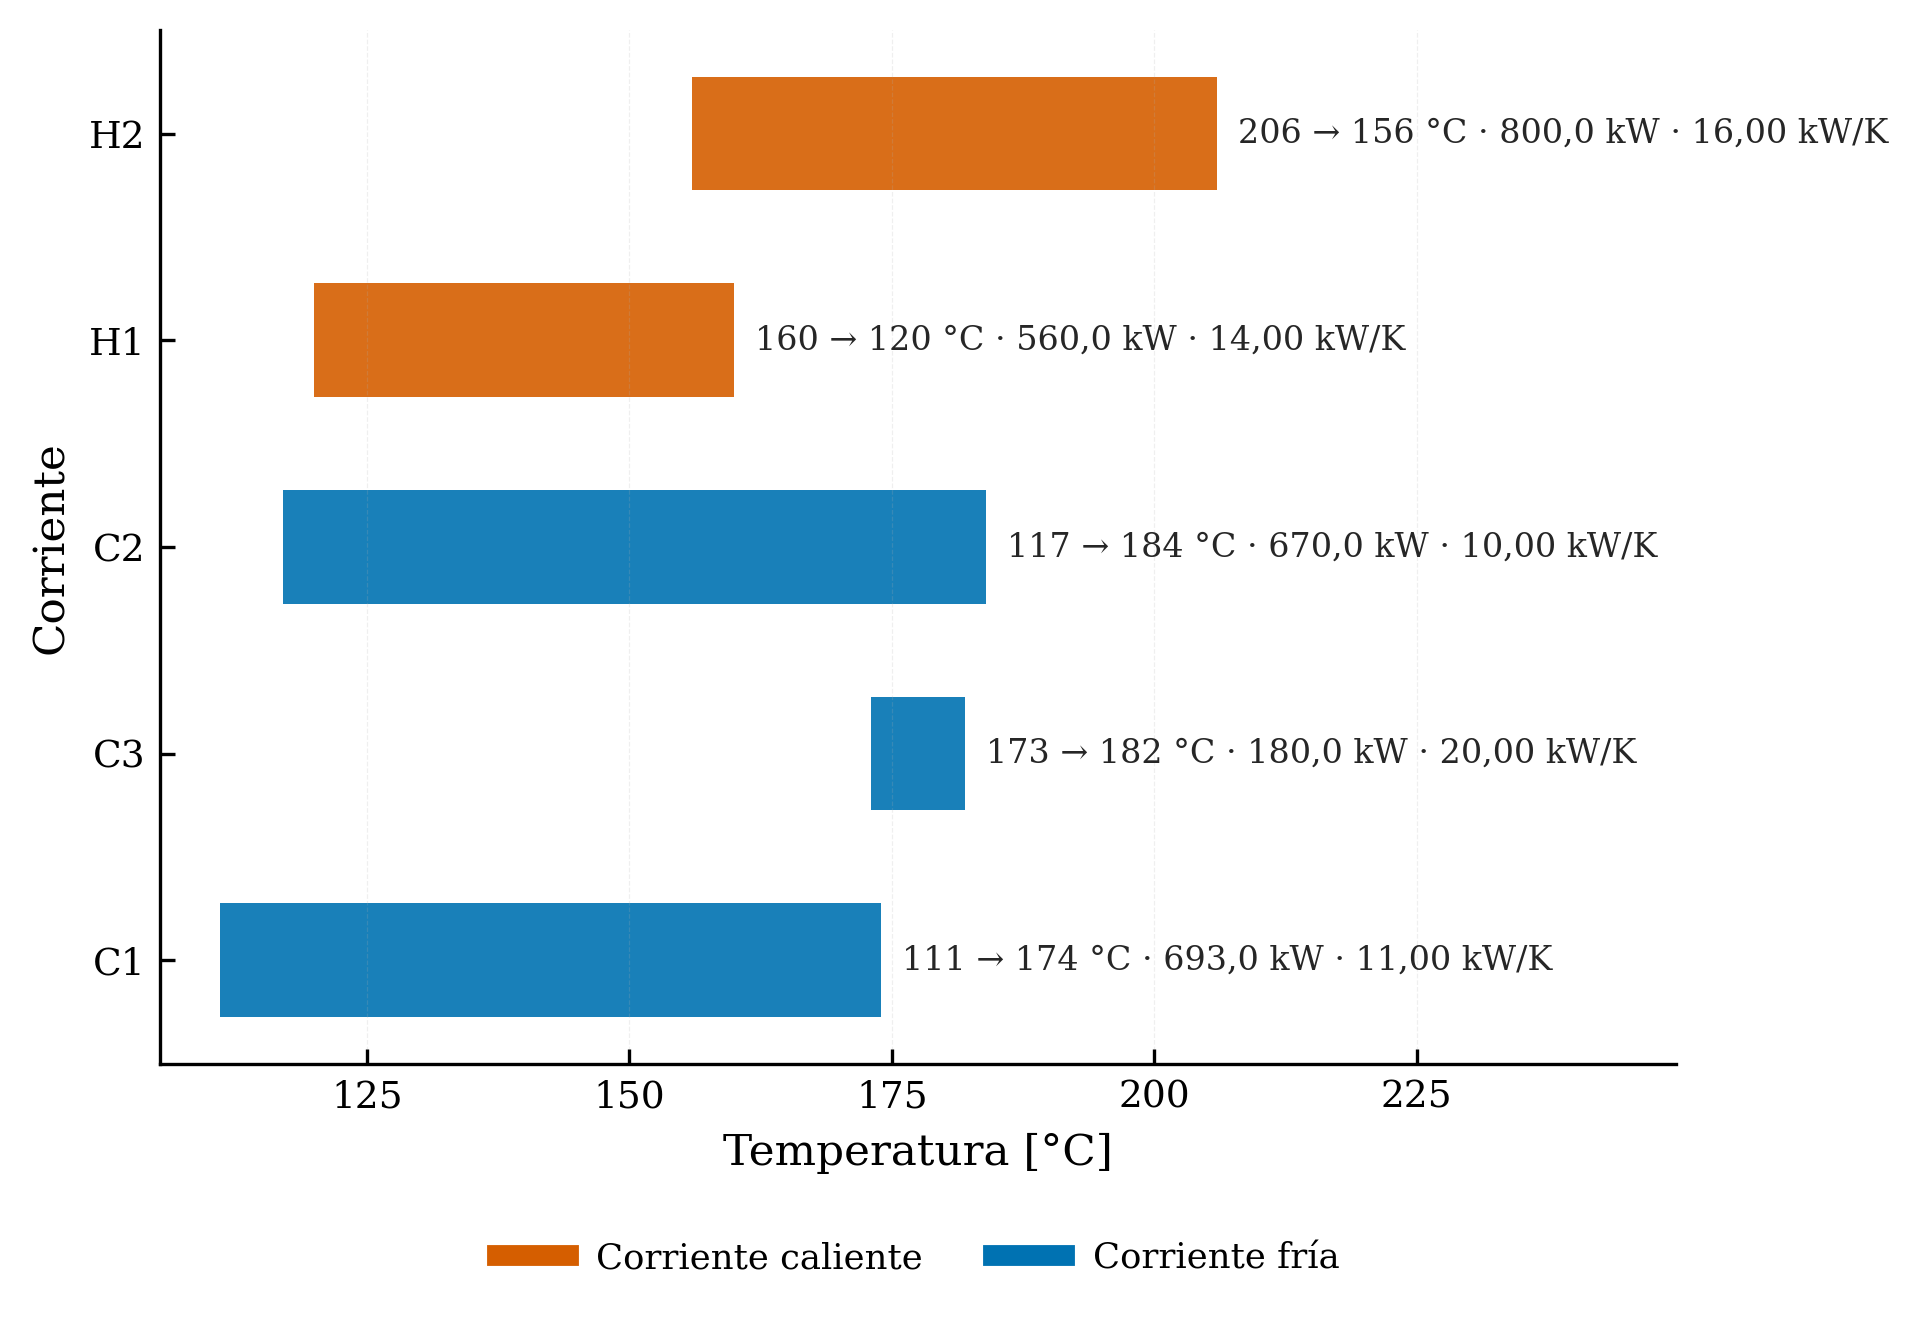

In [3]:
fig_bars = plot_stream_bars(streams)

## S2. Cargas totales y cierre de Primera Ley

Primero se ejecuta el análisis con una aproximación mínima de 10 K y un corrimiento por corriente de 5 K. Después se audita el balance con `verify_first_law`: la identidad comprobada es que la diferencia entre las dos utilidades iguala el déficit neto del proceso. La auditoría se repite contra el resultado de Pinch y con una tolerancia estricta de un milésimo de kilovatio.

In [4]:
result = run_pinch(streams, dT_min=10.0, dt_cont_K=5.0)
report_fl = verify_first_law(streams)
report_fl_pinched = verify_first_law(streams, result)
report_fl_strict = verify_first_law(streams, result, tolerance_kW=1e-3)

print(f"Entalpía liberada por las corrientes calientes: {report_fl.hot_kW:.3f} kW")
print(f"Entalpía demandada por las corrientes frías: {report_fl.cold_kW:.3f} kW")
print(f"Déficit neto del proceso: {report_fl.difference_kW:.3f} kW")
print(f"Residuo de balance de Primera Ley: {report_fl.residual_kW:.3e} kW")
print(f"Balance cerrado con la tolerancia por omisión: {report_fl.closes}")
print(f"Tolerancia aplicada por omisión: {report_fl.tolerance_kW:.3e} kW")
print(f"Cierre auditado contra el resultado de Pinch: {report_fl_pinched.closes}")
print(f"Cierre con tolerancia estricta: {report_fl_strict.closes}")
print(f"Tolerancia estricta aplicada: {report_fl_strict.tolerance_kW:.3e} kW")

Entalpía liberada por las corrientes calientes: 1360.000 kW
Entalpía demandada por las corrientes frías: 1543.000 kW
Déficit neto del proceso: 183.000 kW
Residuo de balance de Primera Ley: 0.000e+00 kW
Balance cerrado con la tolerancia por omisión: True
Tolerancia aplicada por omisión: 1.000e-06 kW
Cierre auditado contra el resultado de Pinch: True
Cierre con tolerancia estricta: True
Tolerancia estricta aplicada: 1.000e-03 kW


## S3. Límites corridos y tabla de bandas

`problem_table` devuelve las fronteras corridas y la cascada neta medida desde la frontera más caliente. `band_table` devuelve cada banda con su posición, sus límites, su ancho, sus corrientes activas, su balance de tasa de capacidad y su entalpía neta. Refinar el corrimiento a 2.5 K subdivide las bandas sin alterar la suma de entalpías.

In [5]:
bounds, net = problem_table(streams, dt_cont_K=5.0)
bands = band_table(streams, dt_cont_K=5.0)
bands_refined = band_table(streams, dt_cont_K=2.5)
dH_sum_kW = result.dH_sum_kW
dCP_min_kW_per_K = result.dCP_min_kW_per_K

print(f"Fronteras corridas de la tabla del problema: {bounds}")
for b in bands:
    print(
        f"Banda {b.index}: de {b.T_low_C:.1f} °C a {b.T_high_C:.1f} °C, "
        f"ancho {b.width_K:.1f} K, activas {b.active}, "
        f"dCP {b.dCP_kW_per_K:.3f} kW/K, dH {b.dH_kW:.3f} kW"
    )
print(f"Suma de las entalpías netas de todas las bandas: {dH_sum_kW:.3f} kW")
print(f"Mínimo del balance de tasa de capacidad: {dCP_min_kW_per_K:.3f} kW/K")
for b_ref in bands_refined:
    print(
        f"Banda refinada {b_ref.index}: de {b_ref.T_low_C:.1f} °C a {b_ref.T_high_C:.1f} °C, "
        f"ancho {b_ref.width_K:.1f} K, activa {b_ref.active}, "
        f"dCP {b_ref.dCP_kW_per_K:.3f} kW/K, dH {b_ref.dH_kW:.3f} kW"
    )

Fronteras corridas de la tabla del problema: [115.0, 116.0, 122.0, 151.0, 155.0, 178.0, 179.0, 187.0, 189.0, 201.0]
Banda 0: de 115.0 °C a 116.0 °C, ancho 1.0 K, activas ('H1',), dCP -14.000 kW/K, dH -14.000 kW
Banda 1: de 116.0 °C a 122.0 °C, ancho 6.0 K, activas ('H1', 'C1'), dCP -3.000 kW/K, dH -18.000 kW
Banda 2: de 122.0 °C a 151.0 °C, ancho 29.0 K, activas ('H1', 'C1', 'C2'), dCP 7.000 kW/K, dH 203.000 kW
Banda 3: de 151.0 °C a 155.0 °C, ancho 4.0 K, activas ('H1', 'H2', 'C1', 'C2'), dCP -9.000 kW/K, dH -36.000 kW
Banda 4: de 155.0 °C a 178.0 °C, ancho 23.0 K, activas ('H2', 'C1', 'C2'), dCP 5.000 kW/K, dH 115.000 kW
Banda 5: de 178.0 °C a 179.0 °C, ancho 1.0 K, activas ('H2', 'C1', 'C2', 'C3'), dCP 25.000 kW/K, dH 25.000 kW
Banda 6: de 179.0 °C a 187.0 °C, ancho 8.0 K, activas ('H2', 'C2', 'C3'), dCP 14.000 kW/K, dH 112.000 kW
Banda 7: de 187.0 °C a 189.0 °C, ancho 2.0 K, activas ('H2', 'C2'), dCP -6.000 kW/K, dH -12.000 kW
Banda 8: de 189.0 °C a 201.0 °C, ancho 12.0 K, activas 

In [6]:
active_80 = active_streams_at(streams, dt_cont_K=5.0, T_C=80.0)
active_120 = active_streams_at(streams, dt_cont_K=5.0, T_C=120.0)
active_180 = active_streams_at(streams, dt_cont_K=5.0, T_C=180.0)
active_220 = active_streams_at(streams, dt_cont_K=5.0, T_C=220.0)

print(f"Corrientes activas a 80 °C: {active_80}")
print(f"Corrientes activas a 120 °C: {active_120}")
print(f"Corrientes activas a 180 °C: {active_180}")
print(f"Corrientes activas a 220 °C: {active_220}")

Corrientes activas a 80 °C: ()
Corrientes activas a 120 °C: ('H1', 'C1')
Corrientes activas a 180 °C: ('H2', 'C2', 'C3')
Corrientes activas a 220 °C: ()


## S4. Cascada y metas

La cascada se lee como tabla, no como figura. Cada fila es un nivel corrido del problema y trae dos valores: la cascada cruda, que es el calor neto acumulado medido desde el extremo caliente, y la cascada factible, que es la cruda reflejada respecto de la mitad del servicio caliente. La cascada factible es exactamente la ordenada de la Gran Curva Compuesta, de modo que su dibujo se reserva para S10 y aquí se lee en números: en el nivel 187.0 °C la cruda vale -204.0 kW y la factible 419.0 kW, y el punto medio entre ambas es 107.5 kW. Las dos primeras columnas son lecturas directas de la tabla del problema y la tercera es un campo del resultado del motor, sin operación alguna en la celda.

In [7]:
print(f"{'Nivel corrido':>14} {'Cruda':>12} {'Factible':>12}")
print(f"{'[°C]':>14} {'[kW]':>12} {'[kW]':>12}")
for nivel_C, cruda_kW, factible_kW in zip(bounds, net, result.gcc_heat_kW):
    print(f"{nivel_C:>14.1f} {cruda_kW:>12.1f} {factible_kW:>12.1f}")


 Nivel corrido        Cruda     Factible
          [°C]         [kW]         [kW]
         115.0        183.0         32.0
         116.0        197.0         18.0
         122.0        215.0          0.0
         151.0         12.0        203.0
         155.0         48.0        167.0
         178.0        -67.0        282.0
         179.0        -92.0        307.0
         187.0       -204.0        419.0
         189.0       -192.0        407.0
         201.0          0.0        215.0


In [8]:
print(f"Q_H,min = {result.Qh_min_kW:.1f} kW")
print(f"Q_C,min = {result.Qc_min_kW:.1f} kW")
print(f"Q_recuperacion = {result.Qr_kW:.1f} kW")


Q_H,min = 215.0 kW
Q_C,min = 32.0 kW
Q_recuperacion = 1328.0 kW


## S5. Lectura fina de la cascada

Tres agregados del resultado describen la forma de la cascada: su mínimo crudo, el nivel térmico donde ese mínimo ocurre y el margen térmico al segundo nivel. El margen mide cuán lejos está el pliegue del siguiente nivel de la cascada.

In [9]:
raw_cascade_min_kW = result.raw_cascade_min_kW
raw_cascade_min_level_C = result.raw_cascade_min_level_C
second_level_margin_kW = result.second_level_margin_kW

print(f"Mínimo de la cascada neta cruda: {raw_cascade_min_kW:.3f} kW")
print(f"Nivel térmico del mínimo de la cascada neta cruda: {raw_cascade_min_level_C:.1f} °C")
print(f"Margen térmico al segundo nivel de la cascada: {second_level_margin_kW:.3f} kW")

Mínimo de la cascada neta cruda: -204.000 kW
Nivel térmico del mínimo de la cascada neta cruda: 187.0 °C
Margen térmico al segundo nivel de la cascada: 18.000 kW


## S6. Pinch en tres escalas

El pliegue se informa en tres coordenadas: la corrida, que es la del problema, y las dos reales, una para las corrientes calientes y otra para las corrientes frías. Las dos reales se obtienen desplazando la corrida por el corrimiento de cada corriente.

In [10]:
print(f"Aproximación mínima global de temperatura: {result.dT_min_K:.1f} K")
print(f"Corrimiento de factibilidad aplicado por corriente: {result.dt_cont_K:.1f} K")
print(f"Pliegue corrido: {result.T_pinch_shifted_C:.1f} °C")
print(f"Pliegue para corrientes calientes reales: {result.T_pinch_hot_C:.1f} °C")
print(f"Pliegue para corrientes frías reales: {result.T_pinch_cold_C:.1f} °C")

Aproximación mínima global de temperatura: 10.0 K
Corrimiento de factibilidad aplicado por corriente: 5.0 K
Pliegue corrido: 122.0 °C
Pliegue para corrientes calientes reales: 127.0 °C
Pliegue para corrientes frías reales: 117.0 °C


## S7. Contactos de pliegue

Un pliegue puntual toca su mínimo en un solo nivel. Una meseta de pliegue lo toca en varios niveles tabulados a la vez. `pinch_levels_C` entrega todos los niveles donde la cascada factible alcanza su mínimo, y el resultado conserva además su cantidad y sus niveles de contacto.

In [11]:
pinch_levels = pinch_levels_C(streams, dt_cont_K=5.0)
n_contacts = result.n_contacts
contacts_levels = result.contacts_levels_C

print(f"Niveles corridos donde la cascada factible toca su mínimo: {pinch_levels}")
print(f"Cantidad de puntos de contacto de pliegue: {n_contacts}")
print(f"Niveles térmicos de contacto: {contacts_levels}")

Niveles corridos donde la cascada factible toca su mínimo: [122.0]
Cantidad de puntos de contacto de pliegue: 1
Niveles térmicos de contacto: (122.0,)


## S8. Bolsillos

Un bolsillo es un intervalo térmico donde la Gran Curva Compuesta deja de acumular calor. `detect_pockets` busca dos familias: mesetas de flujo nulo y el tramo de cierre de cada máximo interior. El resultado conserva los límites corridos y el ancho de cada bolsillo.

In [12]:
pockets = detect_pockets(result.gcc_temperatures_C, result.gcc_heat_kW, tol_kW=1.0)
n_pockets = result.n_pockets
pocket_bounds = result.pocket_bounds
pocket_widths_K = result.pocket_widths_K

print(f"Intervalos de bolsa detectados sobre la Gran Curva Compuesta: {pockets}")
print(f"Cantidad de bolsas en la Gran Curva Compuesta: {n_pockets}")
print(f"Límites corridos inmutables de cada bolsa: {pocket_bounds}")
print(f"Ancho de cada bolsa: {pocket_widths_K}")

Intervalos de bolsa detectados sobre la Gran Curva Compuesta: [(151.0, 155.0), (187.0, 189.0)]
Cantidad de bolsas en la Gran Curva Compuesta: 2
Límites corridos inmutables de cada bolsa: ((151.0, 155.0), (187.0, 189.0))
Ancho de cada bolsa: (4.0, 2.0)


## S9. Curvas compuestas

Las curvas compuestas dibujan la carga acumulada de cada familia contra la temperatura corrida. La separación horizontal entre ambas curvas es la aproximación disponible en cada nivel y su contacto es el pliegue.

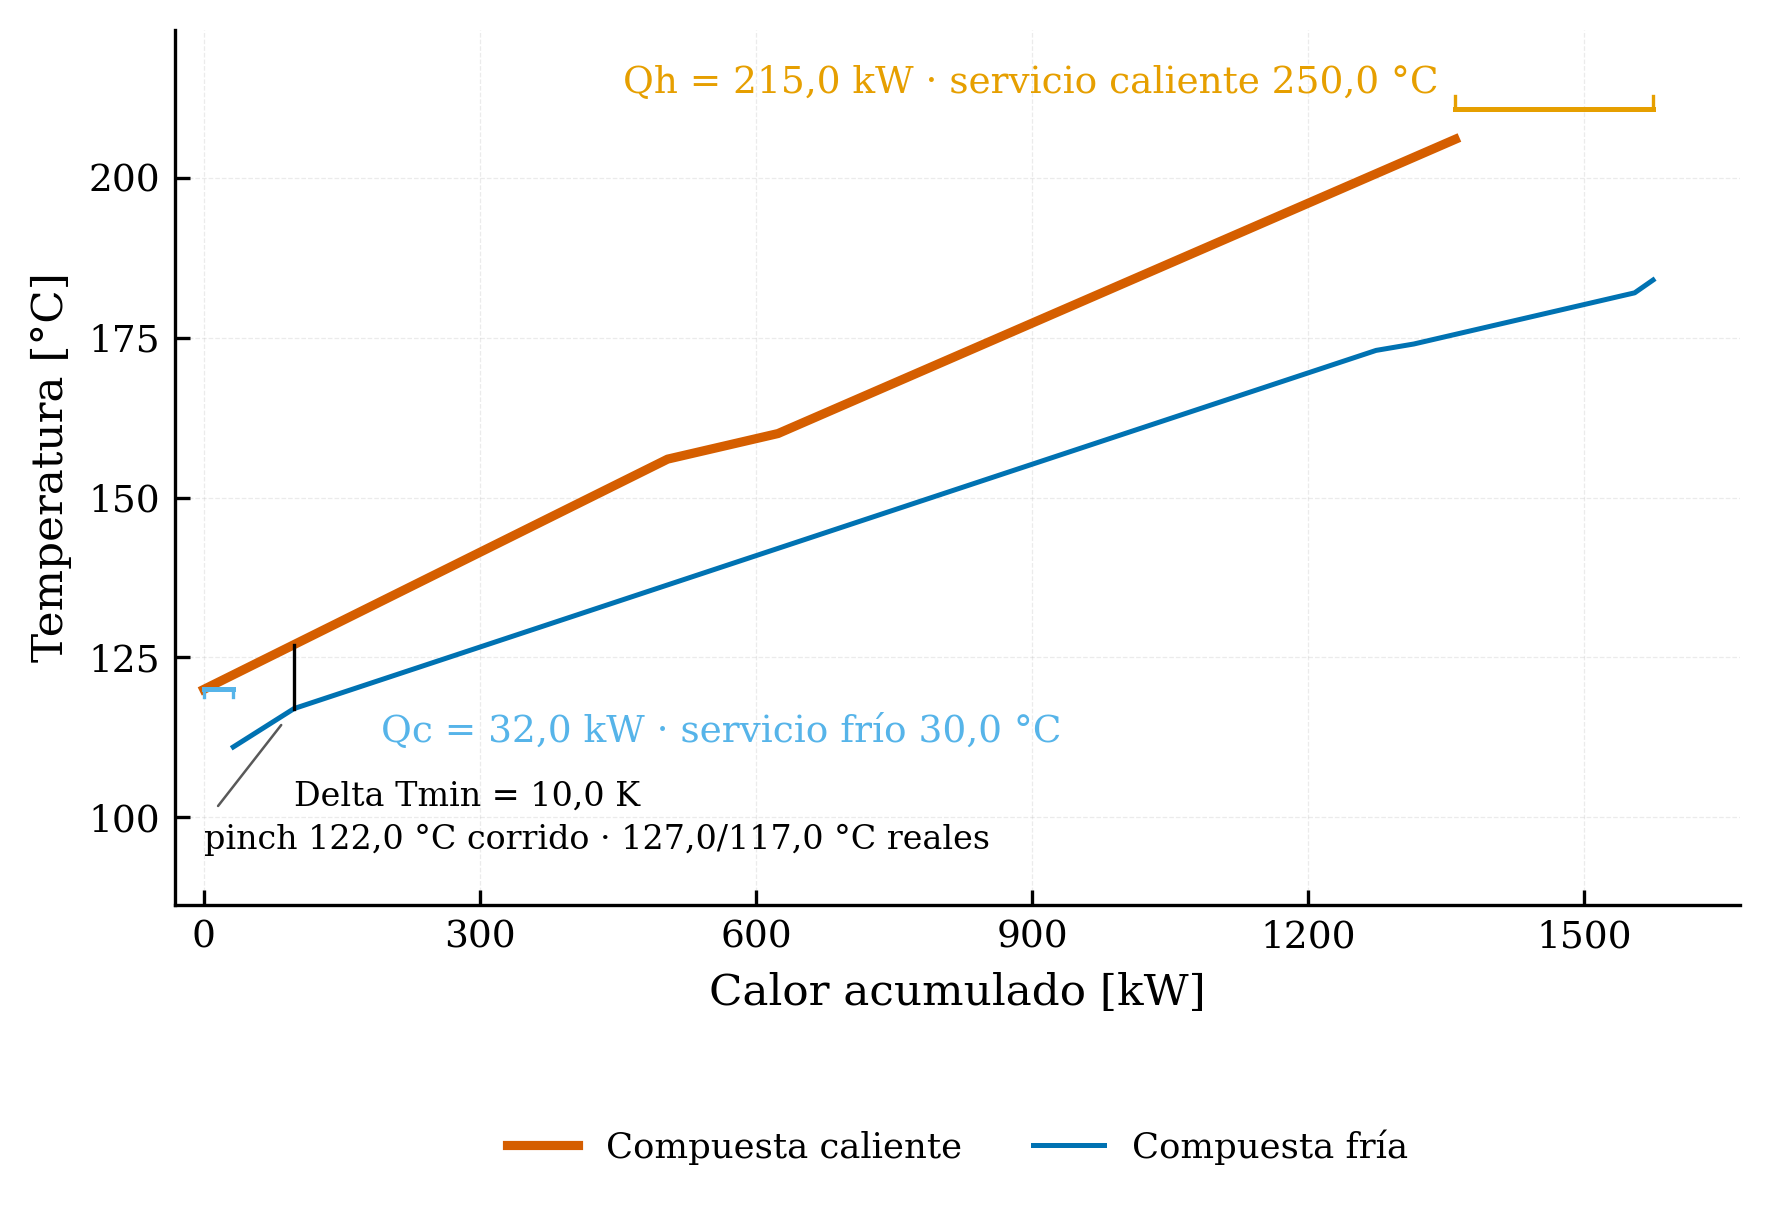

In [13]:
fig_comp = plot_composite_curves(result)

## S10. Gran curva compuesta

La Gran Curva Compuesta entrega el calor acumulado sobre cada nivel. `gcc_deficit_at` lee el flujo acumulado en el nivel de un proceso frío y `gcc_surplus_at` entrega el calor que debe rechazarse bajo el nivel de un proceso caliente.

In [14]:
deficit_120_kW = gcc_deficit_at(result, T_C=120.0)
surplus_120_kW = gcc_surplus_at(result, T_C=120.0)

print(f"Déficit térmico neto de la Gran Curva Compuesta a 120 °C: {deficit_120_kW:.3f} kW")
print(f"Superávit térmico neto de la Gran Curva Compuesta a 120 °C: {surplus_120_kW:.3f} kW")

Déficit térmico neto de la Gran Curva Compuesta a 120 °C: 21.000 kW
Superávit térmico neto de la Gran Curva Compuesta a 120 °C: 0.000 kW


In [ ]:
deficit_140_kW = gcc_deficit_at(result, T_C=140.0)
deficit_100_kW = gcc_deficit_at(result, T_C=100.0)
diferencia_kW = deficit_140_kW - deficit_100_kW

print(f"Deficit termico neto de la Gran Curva Compuesta a 140 C: {deficit_140_kW:.3f} kW")
print(f"Deficit termico neto de la Gran Curva Compuesta a 100 C: {deficit_100_kW:.3f} kW")
print(f"Diferencia entre los dos niveles: {diferencia_kW:.3f} kW")
print("La diferencia es el calor que aporta el nivel superior y que el nivel inferior cubre.")
print(
    "En el caso C53 el pliegue caliente esta en 127 C, de modo que el nivel de 100 C "
    "queda por debajo y la funcion devuelve cero; en un proceso con demanda real a ese "
    "nivel, la diferencia es el reparto que se busca."
)


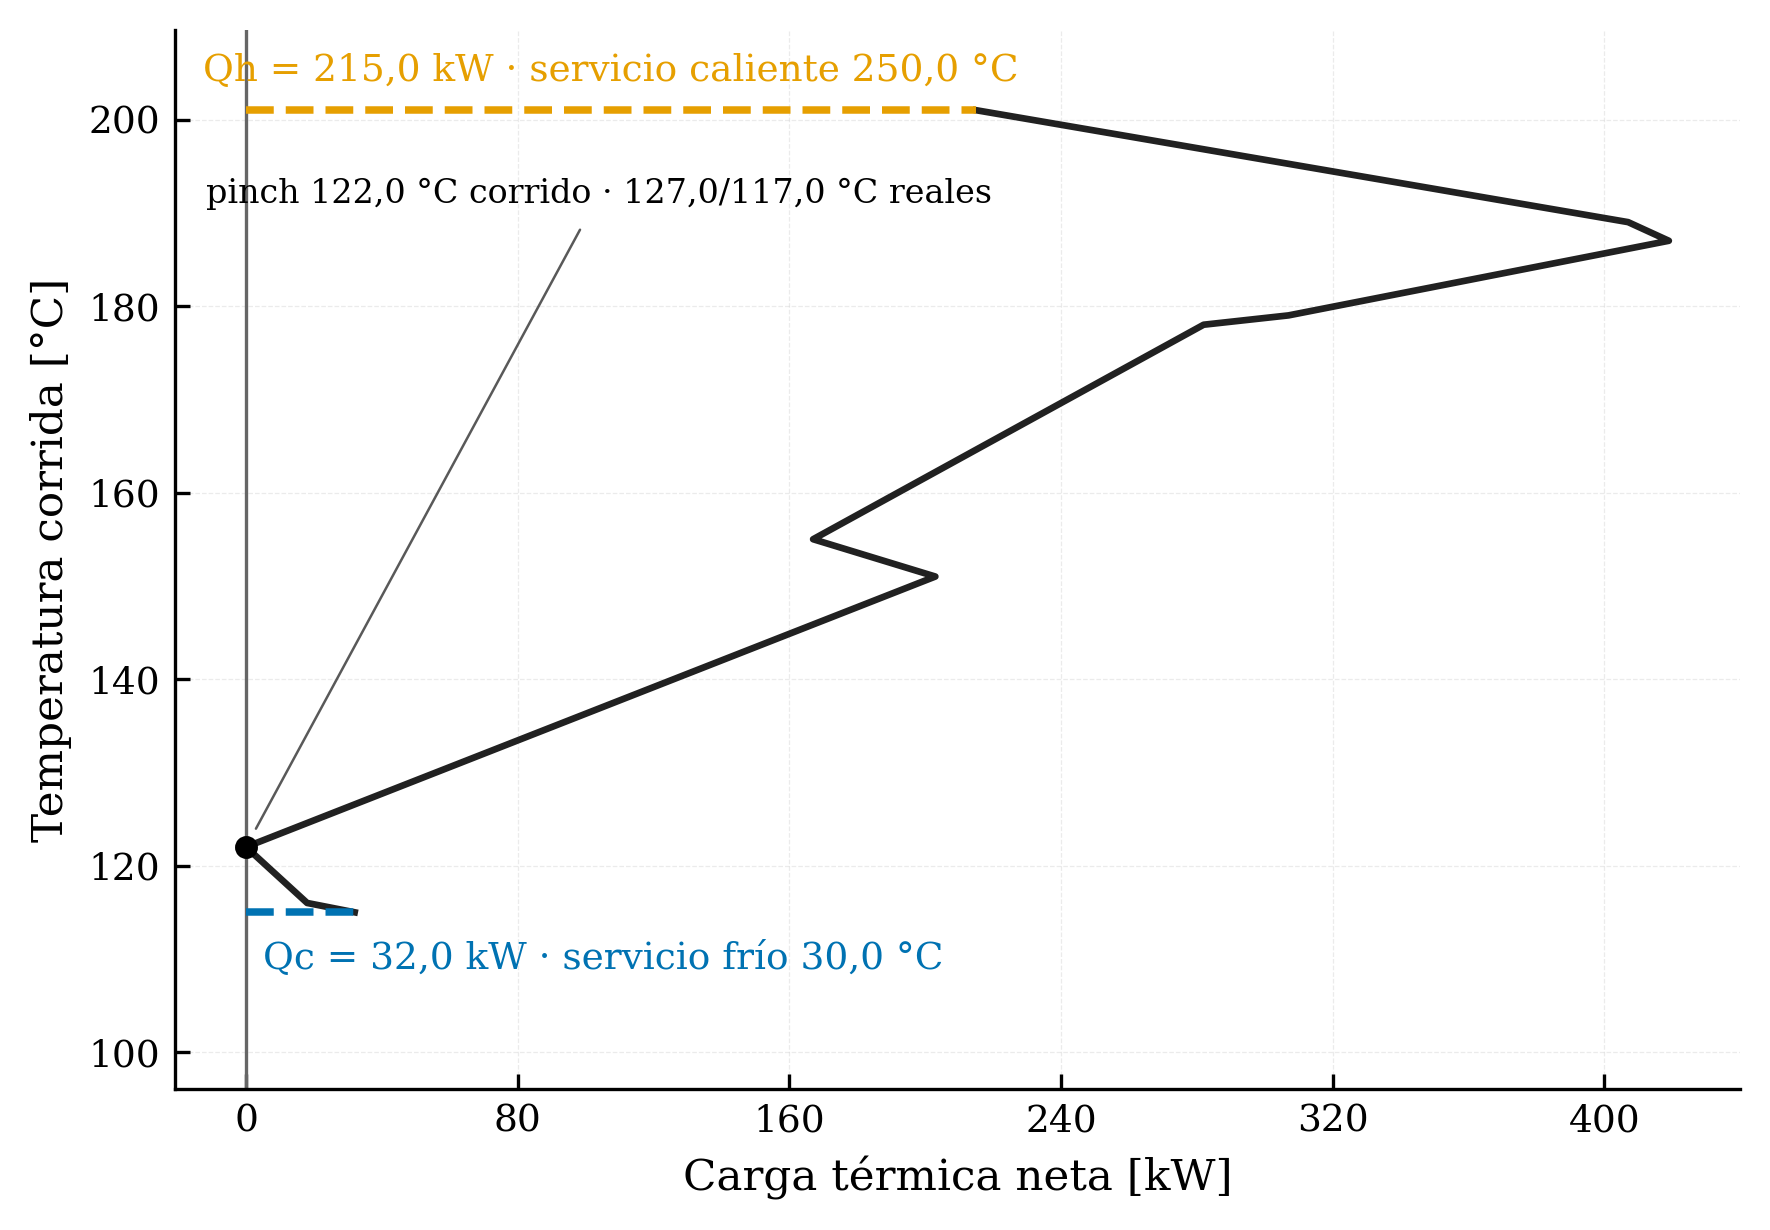

In [15]:
fig_gcc = plot_gcc(result)